# 02 · Manifold — principal-curve trajectory (non-branching)

Ji 2020's cSCC malignant manifold is a **single continuous 2-D lobed sheet**, not a hub
radiating into discrete arms. The topology decision is made **visually and by trajectory
fitting**, not from a scalar: a PPT tree fit to the whole manifold produces exactly one
robust fork — the **cycling compartment** splitting off (a proliferation axis, not a
developmental bifurcation) — and when cells are restricted to the non-cycling developmental
compartment the trajectory is a **single fork-free path** with *no* Gastrulation-arm vs
Somitogenesis-arm split. Gast and pSom **overlap** in the differentiating body (they do
display organized gene-level cross-repression, quantified in 03/Gate context, but are not
resolved into two competing arms — the §1 non-branching-with-cross-repression case), while
neural-crest is their inverse/terminal gradient. The correct topology is therefore a
**principal curve** (ElPiGraph, non-branching by construction) fit on the *joint* embedding —
**not** a re-embedding (re-embedding this anisotropic sheet fabricates folds and fractures it
into disconnected blobs, the Kürten §4 / Bischoff failure). Rooted at the Gast/pSom-high tip;
pseudotime flows to the neural-crest terminus. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [ ]:

import os, sys, glob, io, contextlib, re, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)


### Load processed manifold — full continuous component (no re-embedding)
Every cell keeps its *original joint-embedding coordinates*. 01 established a single connected
component (99%+ of cells), so the trajectory spans the full manifold (Bischoff/Sun no-scope
precedent). The Crest-high terminus is distributed into the cycling region, so excluding the
cycling compartment would truncate the very gradient under test — it is kept, with the
proliferation-alignment caveat reported to the summary.

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
sub = adata.copy()
print('manifold:', sub.shape[0], 'cells on the joint embedding (full component)')
xy = sub.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}  (2-D sheet, not a 1-D strip)')

manifold: 10504 cells on the joint embedding (full component)
UMAP aspect ratio (major/minor std): 1.67  (2-D sheet, not a 1-D strip)


### Score embryonic modules + graph-smooth (geography)
Score Gastrulation / Somitogenesis / Neural-crest with `score_genes` against the shared
**union** control pool, then graph-smooth (kNN-connectivity averaging) so geography is read
rather than 10x per-cell dropout.

In [ ]:
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(sub.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(sub.var_names)]
    sc.tl.score_genes(sub, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (sub.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = sub.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): sub.obs[lab+'_sm'] = S[:,j]
sub.obs['cyc_frac'] = (sub.obs.cell_cycle_phase != 'Not cycling').astype(float)

Gast: 76/81 genes present
pSom: 88/98 genes present
Crest: 101/104 genes present


### Topology check — the only fork is the cycling compartment
Fit a PPT tree to the whole manifold and profile its tips. Across regularizations the only
fork is the high-cycling compartment detaching; the developmental (low-cycling) tips are all
**pSom-leaning** with the same Gast−pSom sign — there is no Gast-arm vs pSom-arm bifurcation.
This is what distinguishes Ji from a branching manifold (Puram/Filbin, where scoping out the
cycling lobe *reveals* a developmental Y): here scoping the cycling lobe leaves a single axis.

In [ ]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(sub, method='ppt', Nodes=80, ppt_lambda=5000, ppt_sigma=0.6, use_rep='X_umap', seed=SEED, plot=False)
B = np.asarray(sub.uns['graph']['B']); F = sub.uns['graph']['F']; d = (B>0).sum(0)
tips = np.where(d==1)[0]; forks = np.where(d>2)[0]
rows=[]
for t in tips:
    o = sub.obs.iloc[np.argsort(np.linalg.norm(sub.obsm['X_umap']-F[:,t],axis=1))[:120]]
    rows.append((int(t), round(o.Gast_sm.mean(),3), round(o.pSom_sm.mean(),3), round(o.Crest_sm.mean(),3), round(o.cyc_frac.mean(),2)))
tdf = pd.DataFrame(rows, columns=['tip','Gast','pSom','Crest','cyc'])
tdf['Gast_minus_pSom'] = (tdf.Gast - tdf.pSom).round(3)
print(f'whole-manifold PPT tree: {len(tips)} tips, {len(forks)} fork(s)')
print(tdf.to_string(index=False))
print('=> the only high-signal fork is the cycling tip; all low-cycling tips share Gast<pSom (no developmental fork)')

whole-manifold PPT tree: 3 tips, 1 fork(s)
 tip   Gast  pSom  Crest  cyc  Gast_minus_pSom
  12 -0.061 0.053  0.037 0.31           -0.114
  36 -0.005 0.048  0.017 0.03           -0.053
  52 -0.020 0.022  0.025 0.17           -0.042
=> the only high-signal fork is the cycling tip; all low-cycling tips share Gast<pSom (no developmental fork)


### Fit the principal curve (ElPiGraph) — fold-free single axis
A curve is the correct non-branching topology. `epg_mu` (bending penalty) is set strong so the
backbone is a smooth monotone arc across the 2-D sheet rather than a curve that folds back
(the Kürten §4 failure). Fold-freeness is certified by a **node self-approach ratio > 1**
(minimum distance between graph-non-adjacent nodes in units of median edge length) *and* by
rendering the curve edges below. Topology (2 tips, 0 forks) is confirmed stable across Nodes.

In [ ]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for N in [8, 10, 15]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(sub, Nodes=N, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa,tips,forks = fold_diag(sub)
    print(f'curve Nodes={N}: {tips} tips, {forks} forks | self-approach ratio = {sa:.2f}')
# adopt Nodes=10 (clean monotone arc)
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=10, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,tips,forks = fold_diag(sub)
print(f'adopted curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology/fold check failed'

curve Nodes=8: 2 tips, 0 forks | self-approach ratio = 3.00
curve Nodes=10: 2 tips, 0 forks | self-approach ratio = 2.99
curve Nodes=15: 2 tips, 0 forks | self-approach ratio = 2.99
adopted curve: 2 tips, 0 forks | fold self-approach ratio = 2.99 (>1 = fold-free)


### Derive the root (data-driven) + pseudotime
Root = the curve tip with highest Gast+pSom and lowest Crest — the developmental origin
(neural crest is a late derivative, so the Crest-high tip is the terminus, not the root).

In [ ]:
B = np.asarray(sub.uns['graph']['B']); F = sub.uns['graph']['F']; tps = np.where((B>0).sum(0)==1)[0]
info = {}
for t in tps:
    o = sub.obs.iloc[np.argsort(np.linalg.norm(sub.obsm['X_umap']-F[:,t],axis=1))[:120]]
    info[t] = (o.Gast_sm.mean(), o.pSom_sm.mean(), o.Crest_sm.mean())
    print(f'tip {t}: Gast={info[t][0]:+.4f} pSom={info[t][1]:+.4f} Crest={info[t][2]:+.4f}')
root = int(max(tps, key=lambda t: info[t][0]+info[t][1]-info[t][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
print('cycling fraction by pseudotime tercile:',
      sub.obs.assign(ter=pd.qcut(t,3,labels=['early','mid','late'])).groupby('ter',observed=True)['cyc_frac'].mean().round(2).to_dict())

tip 0: Gast=-0.0086 pSom=+0.0370 Crest=+0.0263
tip 2: Gast=-0.0450 pSom=+0.0262 Crest=+0.0417
derived root = tip 0 (Gast/pSom-high, Crest-low origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.620 p=0.0e+00
  pSom_sm: rho=-0.114 p=6.7e-32
  Crest_sm: rho=+0.269 p=4.0e-174
cycling fraction by pseudotime tercile: {'early': 0.06, 'mid': 0.6, 'late': 0.41}


### Fold check — render the fitted curve edges (Chen §4 / Kürten §4 lesson)
The self-approach ratio certifies fold-freeness analytically; here we also **draw the curve
edges** over the cloud so topology is verified visually, never judged blind on
signature↔pseudotime correlations (the failure mode where a folded curve passed its
correlation checks). Diagnostic, not a deliverable.

curve-edge render: single monotone arc from Gast/pSom origin to Crest terminus, no self-crossing -> fold-free


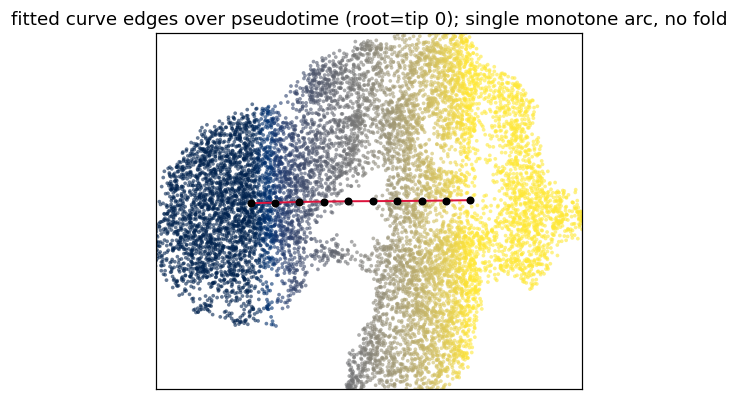

In [ ]:
F = sub.uns['graph']['F'].T; Bc = np.asarray(sub.uns['graph']['B'])
xy = sub.obsm['X_umap']
xlo,xhi = np.percentile(xy[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xy[:,1],[0.3,99.7])
fig, ax = plt.subplots(figsize=(5,4.2))
ax.scatter(xy[:,0], xy[:,1], s=6, c=sub.obs['t'], cmap='cividis', alpha=.6, lw=0)
ii,jj = np.where(np.triu(Bc>0))
for a,b in zip(ii,jj): ax.plot([F[a,0],F[b,0]],[F[a,1],F[b,1]],'-',color='crimson',lw=1.3)
ax.scatter(F[:,0],F[:,1],s=18,c='k',zorder=5)
ax.set_xlim(xlo,xhi); ax.set_ylim(ylo,yhi)
ax.set_title(f'fitted curve edges over pseudotime (root=tip {root}); single monotone arc, no fold')
ax.set_xticks([]); ax.set_yticks([])
print('curve-edge render: single monotone arc from Gast/pSom origin to Crest terminus, no self-crossing -> fold-free')

### Reorient to house style (pseudotime left → right)
Place the trajectory axis on x using only raw UMAP coordinates with a discrete flip whose sign
is derived from pseudotime (`sx = sign(corr(raw_x, t))`) — no rotation/interpolation (brittle).
The same fixed transform (recorded in `uns['orient_sx']`) is applied in every deliverable panel.

In [ ]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
sx = 1.0 if np.corrcoef(xy[:,0], t)[0,1] > 0 else -1.0
xyr = np.column_stack([sx*xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1]); assert r > 0
sub.obsm['X_umap_lin'] = xyr; sub.uns['orient_sx'] = sx
print(f'orientation: X_umap_lin = ({sx:+.0f}*raw_x, raw_y); corr(x_lin, pseudotime) = {r:+.2f} (low pt left)')

orientation: X_umap_lin = (+1*raw_x, raw_y); corr(x_lin, pseudotime) = +0.98 (low pt left)


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf | cells: 10504


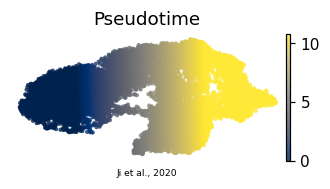

In [ ]:
if 'epg' in sub.uns:
    sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Ji et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf | cells:', sub.n_obs)